# Monte Carlo Simulation Example

### Can random numbers help us estimate $\pi$ ?

# Goal
Estimate the value of $\pi$ (pi) using random points.

# Idea
1. Draw a square of side length 2.
2. Inside the square, draw a circle of radius 1.
3. Randomly generate points in the square. (i.e. Throw a dart inside the square)
4. Count how many fall inside the circle.  (i.e. Count how many darts fall inside circle)

Since:
$$\text{Area of Circle} = \pi r^2 = \pi$$
$$\text{Area of Square} = 4$$

Therefore:
$$\frac{\text{Points inside circle}}{\text{Total points}} \approx \frac{\pi}{4}$$

So:
$$\pi \approx 4 \times \left( \frac{\text{Points inside circle}}{\text{Total points}} \right)$$

This is a classic Monte Carlo simulation.


In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Number of random points
n_points = 5000

# Generate random x and y coordinates between -1 and 1
x = np.random.uniform(-1, 1, n_points)
y = np.random.uniform(-1, 1, n_points)

In [11]:
print("First x points:", x[:5])
print("First y points:", y[:5])

First x points: [ 0.18830738 -0.31009884  0.79331657  0.07844192 -0.73296138]
First y points: [-0.12327864  0.54853071 -0.90159598  0.21884934  0.65643685]


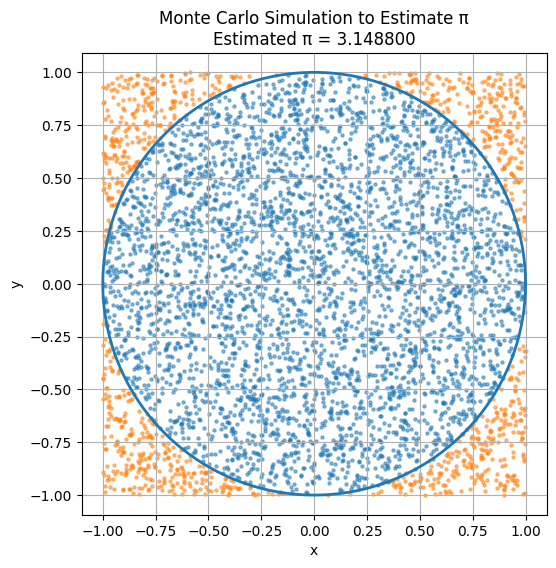

In [13]:
# Visualization

# Distance from origin
distance = x**2 + y**2

# Check whether points are inside the unit circle
inside_circle = distance <= 1

plt.figure(figsize=(6, 6))

# Points inside circle (blue)
plt.scatter(
    x[inside_circle],
    y[inside_circle],
    s=5,
    alpha=0.5,
    label='Inside Circle'
)

# Points outside circle (orange)
plt.scatter(
    x[~inside_circle],
    y[~inside_circle],
    s=5,
    alpha=0.5,
    label='Outside Circle'
)

# Draw circle boundary
theta = np.linspace(0, 2*np.pi, 500)
plt.plot(np.cos(theta), np.sin(theta), linewidth=2, label='Unit Circle')

# Formatting
plt.title(f"Monte Carlo Simulation to Estimate π\nEstimated π = {pi_estimate:.6f}")
plt.xlabel("x")
plt.ylabel("y")
plt.axis('equal')
plt.grid(True)
# plt.legend()
plt.show()

In [7]:
# Distance from origin
distance = x**2 + y**2

# Check whether points are inside the unit circle
inside_circle = distance <= 1

# Count points
points_inside = np.sum(inside_circle)

# Estimate pi
pi_estimate = 4 * points_inside / n_points

print(f"Total Points       : {n_points}")
print(f"Points Inside      : {points_inside}")
print(f"Estimated Pi       : {pi_estimate:.6f}")
print(f"Actual Pi          : {np.pi:.6f}")
print(f"Error              : {abs(np.pi - pi_estimate):.6f}")

Total Points       : 5000
Points Inside      : 3936
Estimated Pi       : 3.148800
Actual Pi          : 3.141593
Error              : 0.007207
